## Task 1: BFS for Minimum-Transfer Public Transport Routing

Initial Queue: ['FAST University']
Start: FAST University, Goal: PIMS Metro Station
--------------------------------------------------
Step 1: EXPAND -> FAST University | Level: 0
  Added to queue: []
  Queue now: ['NUST Metro Station', 'G-11 Metro Station', 'H-8 Metro Station']

Step 2: EXPAND -> NUST Metro Station | Level: 1
  Added to queue: []
  Queue now: ['G-11 Metro Station', 'H-8 Metro Station', 'Faiz Ahmed Faiz Metro Station', 'Saddar Metro Station']

Step 3: EXPAND -> G-11 Metro Station | Level: 1
  Added to queue: []
  Queue now: ['H-8 Metro Station', 'Faiz Ahmed Faiz Metro Station', 'Saddar Metro Station']

Step 4: EXPAND -> H-8 Metro Station | Level: 1
  Added to queue: []
  Queue now: ['Faiz Ahmed Faiz Metro Station', 'Saddar Metro Station', 'I-8 Metro Station']

Step 5: EXPAND -> Faiz Ahmed Faiz Metro Station | Level: 2
  Added to queue: []
  Queue now: ['Saddar Metro Station', 'I-8 Metro Station', 'PIMS Metro Station']

Step 6: EXPAND -> Saddar Metro Station | Level: 2


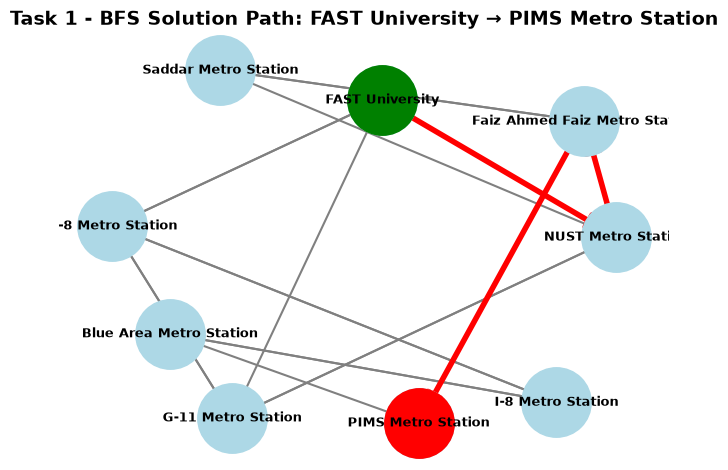

In [7]:
from collections import deque
import networkx as nx
import matplotlib.pyplot as plt

# 1. Transportation Network (Islamabad Metro/Bus Network)
# Based on lab task: FAST University -> NUST -> Faiz Ahmed Faiz -> PIMS (3 transitions)
# Alternative connections added so BFS explores multiple branches
graph = {
    "FAST University": [
        "NUST Metro Station",
        "G-11 Metro Station",
        "H-8 Metro Station"
    ],

    "NUST Metro Station": [
        "Faiz Ahmed Faiz Metro Station",
        "Saddar Metro Station",
        "G-11 Metro Station"
    ],

    "G-11 Metro Station": [
        "NUST Metro Station",
        "H-8 Metro Station"
    ],

    "H-8 Metro Station": [
        "FAST University",
        "G-11 Metro Station",
        "I-8 Metro Station"
    ],

    "Saddar Metro Station": [
        "Faiz Ahmed Faiz Metro Station"
    ],

    "Faiz Ahmed Faiz Metro Station": [
        "PIMS Metro Station",
        "Saddar Metro Station"
    ],

    "I-8 Metro Station": [
        "H-8 Metro Station",
        "Blue Area Metro Station"
    ],

    "Blue Area Metro Station": [
        "I-8 Metro Station",
        "PIMS Metro Station"
    ],

    "PIMS Metro Station": []
}

# 2. BFS Function - Complete Implementation

def bfs(graph, start, goal):
    """
    Breadth-First Search implementation for unweighted graph.
    Returns: (expansion_order, levels_dict, solution_path)
    """
    # Frontier: FIFO queue for BFS (level-by-level exploration)
    queue = deque([start])
    
    # Visited set: tracks explored nodes to avoid cycles/repetition
    visited = set()
    
    # Parent dictionary: for path reconstruction (child -> parent)
    parent = {start: None}
    
    # Level dictionary: distance from start in terms of edges
    level = {start: 0}

    # Record order of node expansion (when popped from queue)
    expansion_order = []

    print(f"Initial Queue: {list(queue)}")
    print(f"Start: {start}, Goal: {goal}")
    print("-" * 50)

    step = 0
    while queue:
        step += 1
        # FIFO: pop from left (oldest node = shallowest level)
        current = queue.popleft()
        
        # Record expansion order
        expansion_order.append(current)
        
        # Goal test WHEN NODE IS REMOVED FROM QUEUE (not when added)
        # This guarantees optimal path in unweighted graphs
        if current == goal:
            print(f"Step {step}: EXPAND -> {current}  *** GOAL FOUND ***")
            print(f"Queue after: {list(queue)}")
            break
        
        # Mark as visited AFTER expansion (standard graph search)
        visited.add(current)
        
        print(f"Step {step}: EXPAND -> {current} | Level: {level[current]}")
        
        # Expand neighbors
        for neighbor in graph[current]:
            if neighbor not in visited and neighbor not in queue:
                queue.append(neighbor)
                parent[neighbor] = current
                level[neighbor] = level[current] + 1
        
        added = [n for n in graph[current] if n not in visited and n not in queue]
        print(f"  Added to queue: {added}")
        print(f"  Queue now: {list(queue)}")
        print()

    # Reconstruct Solution Path using parent pointers
    path = []
    node = goal
    if goal in parent:  # Goal was reached
        while node is not None:
            path.append(node)
            node = parent[node]
        path.reverse()
    else:
        path = []  # No path found

    return expansion_order, level, path


# 3. Run BFS
start = "FAST University"
goal = "PIMS Metro Station"

order, levels, path = bfs(
    graph,
    start,
    goal
)

# 4. Display Results
print("=" * 60)
print(" RESULTS OF BFS SEARCH ")
print("=" * 60)
print(f"Initial State: {start}")
print(f"Goal State: {goal}")

print("\nLevels (distance from start):")
for node in path:
    print(f"  Level {levels[node]}: {node}")

print("\nTraversal / Expansion Order:")
for i, node in enumerate(order):
    print(f"  {i+1}. {node}")

print("\nSolution Path:")
print(" → ".join(path))

print(f"\nNumber of Transitions: {len(path) - 1}")

# 5. NetworkX Visualization
G = nx.DiGraph()

# Add all nodes and edges from graph dictionary
for node in graph:
    for neighbor in graph[node]:
        G.add_edge(node, neighbor)

# Use spring layout for automatic positioning
pos = nx.spring_layout(G, seed=42, k=2.5)

# Draw all nodes
nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=2500, node_shape='o')

# Highlight start node (green) and goal node (red)
nx.draw_networkx_nodes(G, pos, nodelist=[start], node_color='green', node_size=2500)
nx.draw_networkx_nodes(G, pos, nodelist=[goal], node_color='red', node_size=2500)

# Draw all edges with arrows
nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=20, width=1.5)

# Draw node labels
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold')

# Highlight solution path in RED with thicker lines
if len(path) > 1:
    path_edges = list(zip(path, path[1:]))
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color='red', width=4, arrows=True, arrowsize=25)

plt.title("Task 1 - BFS Solution Path: FAST University → PIMS Metro Station", fontsize=14, fontweight='bold')
plt.axis("off")
plt.tight_layout()
plt.show()

## Task 2: Tree Search vs Graph Search

In [5]:
from collections import deque
import networkx as nx
import matplotlib.pyplot as plt

# TASK 2: PART 1 - BFS ON TREE WITHOUT VISITED SET
# Hospital navigation tree (no cycles)

tree = {
    "Main Entrance": ["Reception", "Emergency Lobby"],
    "Reception": ["Registration"],
    "Registration": ["Main Corridor"],
    "Main Corridor": [],
    "Emergency Lobby": ["Waiting Area"],
    "Waiting Area": ["Radiology Department"],
    "Radiology Department": []
}

def bfs_tree(graph, start, goal):
    """BFS on tree - no visited set needed (no cycles in tree)."""
    queue = deque([start])
    parent = {start: None}
    traversal_order = []

    print(f"Initial Queue: {list(queue)}")
    print("-" * 50)

    step = 0
    while queue:
        step += 1
        current = queue.popleft()
        traversal_order.append(current)

        if current == goal:
            print(f"Step {step}: POP -> {current}  *** GOAL FOUND ***")
            break

        print(f"Step {step}: POP -> {current}")
        
        for neighbor in graph[current]:
            if neighbor not in parent:  # Not already in queue
                queue.append(neighbor)
                parent[neighbor] = current
        
        print(f"  Queue now: {list(queue)}")
        print()

    # Reconstruct path
    path = []
    node = goal
    if goal in parent:
        while node is not None:
            path.append(node)
            node = parent[node]
        path.reverse()

    return traversal_order, path


start = "Main Entrance"
goal = "Radiology Department"

order, path = bfs_tree(tree, start, goal)

print("=" * 50)
print("PART 1: BFS ON TREE (No Visited Set)")
print("=" * 50)
print("\nTraversal Order:")
print(" \u2192 ".join(order))
print("\nSolution Path:")
print(" \u2192 ".join(path))

print("\nOBSERVATION: Tree has no cycles, so no repeated states.")
print("Visited set is NOT needed for cycle prevention in trees.")

Initial Queue: ['Main Entrance']
--------------------------------------------------
Step 1: POP -> Main Entrance
  Queue now: ['Reception', 'Emergency Lobby']

Step 2: POP -> Reception
  Queue now: ['Emergency Lobby', 'Registration']

Step 3: POP -> Emergency Lobby
  Queue now: ['Registration', 'Waiting Area']

Step 4: POP -> Registration
  Queue now: ['Waiting Area', 'Main Corridor']

Step 5: POP -> Waiting Area
  Queue now: ['Main Corridor', 'Radiology Department']

Step 6: POP -> Main Corridor
  Queue now: ['Radiology Department']

Step 7: POP -> Radiology Department  *** GOAL FOUND ***
PART 1: BFS ON TREE (No Visited Set)

Traversal Order:
Main Entrance → Reception → Emergency Lobby → Registration → Waiting Area → Main Corridor → Radiology Department

Solution Path:
Main Entrance → Emergency Lobby → Waiting Area → Radiology Department

OBSERVATION: Tree has no cycles, so no repeated states.
Visited set is NOT needed for cycle prevention in trees.


## Part 2A: BFS on Graph WITHOUT Visited Set

In [8]:
from collections import deque

# TASK 2: PART 2A - BFS ON GRAPH WITHOUT VISITED SET
# Hospital graph WITH cycle: Main Corridor <-> Waiting Area

hospital_graph = {
    "Main Entrance": ["Reception", "Emergency Lobby"],
    "Reception": ["Registration"],
    "Registration": ["Main Corridor"],
    "Main Corridor": ["Waiting Area"],
    "Emergency Lobby": ["Waiting Area"],
    "Waiting Area": ["Radiology Department", "Main Corridor"],
    "Radiology Department": []
}

def bfs_without_visited(graph, start, goal, max_steps=15):
    """BFS WITHOUT visited set - demonstrates repeated states in cyclic graph."""
    queue = deque([start])
    parent = {start: None}
    step_log = []

    print(f"{'Step':<6} {'Current':<20} {'Added':<30} {'Queue'}")
    print("-" * 80)

    step = 0
    while queue and step < max_steps:
        step += 1
        current = queue.popleft()

        if current == goal:
            print(f"{step:<6} {current:<20} {'*** GOAL FOUND ***':<30} {list(queue)}")
            break

        # Add ALL neighbors without checking visited
        added = []
        for neighbor in graph[current]:
            queue.append(neighbor)
            added.append(neighbor)

        print(f"{step:<6} {current:<20} {str(added):<30} {list(queue)}")
        step_log.append((current, added, list(queue)))

    if step >= max_steps:
        print("\n*** SAFETY LIMIT REACHED - Search would continue indefinitely ***")
        print("This demonstrates the problem: without visited set, cycles cause")
        print("the same states to be generated repeatedly.")

    return step_log


print("=" * 80)
print("PART 2A: BFS ON GRAPH WITHOUT VISITED SET")
print("=" * 80)
print("Graph has cycle: Main Corridor <-> Waiting Area")
print("No visited set -> repeated states will appear\n")

log = bfs_without_visited(hospital_graph, "Main Entrance", "Radiology Department")

print("\nOBSERVATION: Main Corridor and Waiting Area keep appearing in queue.")
print("Without visited set, the search cannot detect and skip repeated states.")
print("This can lead to infinite loops in cyclic graphs.")

PART 2A: BFS ON GRAPH WITHOUT VISITED SET
Graph has cycle: Main Corridor <-> Waiting Area
No visited set -> repeated states will appear

Step   Current              Added                          Queue
--------------------------------------------------------------------------------
1      Main Entrance        ['Reception', 'Emergency Lobby'] ['Reception', 'Emergency Lobby']
2      Reception            ['Registration']               ['Emergency Lobby', 'Registration']
3      Emergency Lobby      ['Waiting Area']               ['Registration', 'Waiting Area']
4      Registration         ['Main Corridor']              ['Waiting Area', 'Main Corridor']
5      Waiting Area         ['Radiology Department', 'Main Corridor'] ['Main Corridor', 'Radiology Department', 'Main Corridor']
6      Main Corridor        ['Waiting Area']               ['Radiology Department', 'Main Corridor', 'Waiting Area']
7      Radiology Department *** GOAL FOUND ***             ['Main Corridor', 'Waiting Area']

OBS

the real problem demonstrated by this implementation is that repeated states continue to be generated, and if the goal were unreachable, the search could continue indefinitely.

The max_steps parameter is therefore only a safety limit for the demonstration, it is not part of the BFS concept.

## Part 2B: BFS on Graph WITH Visited Set

In [9]:
from collections import deque

# TASK 2: PART 2B - BFS ON GRAPH WITH VISITED SET
# Same hospital graph with cycle, but now WITH visited set

def bfs_graph(graph, start, goal):
    """BFS WITH visited set - handles cycles correctly."""
    queue = deque([start])
    visited = set()
    parent = {start: None}
    traversal_order = []

    print(f"{'Step':<6} {'Current':<20} {'Added':<30} {'Queue'}")
    print("-" * 80)

    step = 0
    while queue:
        step += 1
        current = queue.popleft()
        traversal_order.append(current)

        if current == goal:
            print(f"{step:<6} {current:<20} {'*** GOAL FOUND ***':<30} {list(queue)}")
            break

        if current in visited:
            print(f"{step:<6} {current:<20} {'(already visited, skip)':<30} {list(queue)}")
            continue

        visited.add(current)

        added = []
        for neighbor in graph[current]:
            if neighbor not in visited:
                queue.append(neighbor)
                parent[neighbor] = current
                added.append(neighbor)

        print(f"{step:<6} {current:<20} {str(added):<30} {list(queue)}")

    # Reconstruct path
    path = []
    node = goal
    if goal in parent:
        while node is not None:
            path.append(node)
            node = parent[node]
        path.reverse()

    return traversal_order, visited, path


print("=" * 80)
print("PART 2B: BFS ON GRAPH WITH VISITED SET")
print("=" * 80)
print("Same graph with cycle, but WITH visited set\n")

order, visited, path = bfs_graph(hospital_graph, "Main Entrance", "Radiology Department")

print("\n" + "=" * 50)
print("RESULTS")
print("=" * 50)
print("\nTraversal Order:")
print(" \u2192 ".join(order))
print("\nVisited Set:")
print(visited)
print("\nSolution Path:")
print(" \u2192 ".join(path))

print("\nOBSERVATION: Visited set prevents revisiting Main Corridor and Waiting Area.")
print("The cycle is handled correctly. Search terminates normally.")

PART 2B: BFS ON GRAPH WITH VISITED SET
Same graph with cycle, but WITH visited set

Step   Current              Added                          Queue
--------------------------------------------------------------------------------
1      Main Entrance        ['Reception', 'Emergency Lobby'] ['Reception', 'Emergency Lobby']
2      Reception            ['Registration']               ['Emergency Lobby', 'Registration']
3      Emergency Lobby      ['Waiting Area']               ['Registration', 'Waiting Area']
4      Registration         ['Main Corridor']              ['Waiting Area', 'Main Corridor']
5      Waiting Area         ['Radiology Department', 'Main Corridor'] ['Main Corridor', 'Radiology Department', 'Main Corridor']
6      Main Corridor        []                             ['Radiology Department', 'Main Corridor']
7      Radiology Department *** GOAL FOUND ***             ['Main Corridor']

RESULTS

Traversal Order:
Main Entrance → Reception → Emergency Lobby → Registration → W

## NetworkX Visualization

In [ ]:
# TASK 2 VISUALIZATION
G = nx.DiGraph()

for node in hospital_graph:
    for neighbor in hospital_graph[node]:
        G.add_edge(node, neighbor)

pos = nx.spring_layout(G, seed=42, k=2.5)

# Draw nodes
nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=2500)
nx.draw_networkx_nodes(G, pos, nodelist=["Main Entrance"], node_color='green', node_size=2500)
nx.draw_networkx_nodes(G, pos, nodelist=["Radiology Department"], node_color='red', node_size=2500)

# Draw edges
nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=20, width=1.5)

# Labels
nx.draw_networkx_labels(G, pos, font_size=8, font_weight='bold')

# Highlight solution path
if len(path) > 1:
    path_edges = list(zip(path, path[1:]))
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color='red', width=4, arrows=True, arrowsize=25)

plt.title("Task 2 - Hospital Graph (Cycle: Main Corridor <-> Waiting Area)", fontsize=12, fontweight='bold')
plt.axis("off")
plt.tight_layout()
plt.show()

## Task 3: DFS for Warehouse Robot Exploration

Initial Stack: ['Receiving Area']
Start: Receiving Area, Goal: Inspection Area
--------------------------------------------------
Step 1: POP -> Receiving Area | EXPAND neighbors
  Pushed to stack (reversed order): ['Main Aisle']
  Stack now: ['Main Aisle']

Step 2: POP -> Main Aisle | EXPAND neighbors
  Pushed to stack (reversed order): ['Packaging', 'Grocery', 'Electronics']
  Stack now: ['Packaging', 'Grocery', 'Electronics']

Step 3: POP -> Electronics | EXPAND neighbors
  Pushed to stack (reversed order): ['Laptops', 'Phones']
  Stack now: ['Packaging', 'Grocery', 'Laptops', 'Phones']

Step 4: POP -> Phones | EXPAND neighbors
  Pushed to stack (reversed order): ['Inspection Area']
  Stack now: ['Packaging', 'Grocery', 'Laptops', 'Inspection Area']

Step 5: POP -> Inspection Area  *** GOAL FOUND ***
Stack now: ['Packaging', 'Grocery', 'Laptops']
 RESULTS OF DFS SEARCH 
Start: Receiving Area, Goal: Inspection Area

Traversal / Expansion Order:
  1. Receiving Area
  2. Main Aisle
  3

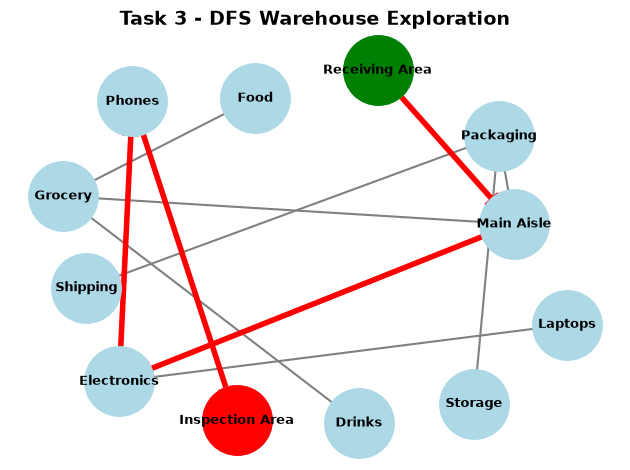

In [10]:
from collections import deque
import networkx as nx
import matplotlib.pyplot as plt

# TASK 3: DFS - WAREHOUSE ROBOT
# Robot: Receiving Area -> Inspection Area
# DFS explores deep first, then backtracks

warehouse = {
    "Receiving Area": ["Main Aisle"],
    "Main Aisle": ["Electronics", "Grocery", "Packaging"],
    "Electronics": ["Phones", "Laptops"],
    "Phones": ["Inspection Area"],
    "Laptops": [],
    "Grocery": ["Food", "Drinks"],
    "Food": [],
    "Drinks": [],
    "Packaging": ["Storage", "Shipping"],
    "Storage": [],
    "Shipping": [],
    "Inspection Area": []
}

def dfs(graph, start, goal):
    """
    Depth-First Search using LIFO stack.
    Returns: (traversal_order, solution_path, visited_set)
    """
    # LIFO stack - most recent node is explored first (deepest path)
    stack = [start]
    
    # Visited set to avoid cycles
    visited = set()
    
    # Parent dictionary for path reconstruction
    parent = {start: None}
    
    # Record traversal order (when popped from stack)
    traversal_order = []

    print(f"Initial Stack: {stack}")
    print(f"Start: {start}, Goal: {goal}")
    print("-" * 50)

    step = 0
    while stack:
        step += 1
        # LIFO: pop from end (most recent = deepest node)
        current = stack.pop()
        
        # Record traversal order
        traversal_order.append(current)
        
        # Goal test WHEN POPPED FROM STACK
        if current == goal:
            print(f"Step {step}: POP -> {current}  *** GOAL FOUND ***")
            print(f"Stack now: {stack}")
            break
        
        # Skip if already visited (already expanded before)
        if current in visited:
            print(f"Step {step}: POP -> {current} (already visited, skip)")
            continue
        
        # Mark as visited
        visited.add(current)
        
        print(f"Step {step}: POP -> {current} | EXPAND neighbors")
        
        # Add neighbors to stack (reversed so leftmost neighbor is explored first)
        neighbors_added = []
        for neighbor in reversed(graph[current]):
            if neighbor not in visited:
                stack.append(neighbor)
                parent[neighbor] = current
                neighbors_added.append(neighbor)
        
        print(f"  Pushed to stack (reversed order): {neighbors_added}")
        print(f"  Stack now: {stack}")
        print()

    # Reconstruct Solution Path using parent pointers
    path = []
    node = goal
    if goal in parent:
        while node is not None:
            path.append(node)
            node = parent[node]
        path.reverse()
    else:
        path = []

    return traversal_order, path, visited


# Run DFS
start = "Receiving Area"
goal = "Inspection Area"

order, path, visited = dfs(warehouse, start, goal)

# Display Results
print("=" * 60)
print(" RESULTS OF DFS SEARCH ")
print("=" * 60)
print(f"Start: {start}, Goal: {goal}")

print("\nTraversal / Expansion Order:")
for i, node in enumerate(order):
    print(f"  {i+1}. {node}")

print("\nSolution Path:")
print(" \u2192 ".join(path))

print(f"\nNumber of States Explored: {len(visited)}")

# NetworkX Visualization
G = nx.DiGraph()

for node in warehouse:
    for neighbor in warehouse[node]:
        G.add_edge(node, neighbor)

pos = nx.spring_layout(G, seed=42, k=2.5)

# Draw all nodes
nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=2500)

# Highlight start (green), goal (red)
nx.draw_networkx_nodes(G, pos, nodelist=[start], node_color='green', node_size=2500)
nx.draw_networkx_nodes(G, pos, nodelist=[goal], node_color='red', node_size=2500)

# Draw edges
nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=20, width=1.5)

# Labels
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold')

# Highlight solution path in RED
if len(path) > 1:
    path_edges = list(zip(path, path[1:]))
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color='red', width=4, arrows=True, arrowsize=25)

plt.title("Task 3 - DFS Warehouse Exploration", fontsize=14, fontweight='bold')
plt.axis("off")
plt.tight_layout()
plt.show()

## Task 4: UCS for Delivery Route Optimization

Initial PQ: [(0, 'Islamabad Delivery Hub')]
Start: Islamabad Delivery Hub, Goal: Blue Area Delivery Point
--------------------------------------------------
Step 1: POP -> Islamabad Delivery Hub (cost=0) | EXPAND
  Add I-8 Markaz: cost=4 (via Islamabad Delivery Hub)
  Add H-8 Markaz: cost=2 (via Islamabad Delivery Hub)
  PQ now: [(2, 'H-8 Markaz'), (4, 'I-8 Markaz')]

Step 2: POP -> H-8 Markaz (cost=2) | EXPAND
  Add G-8 Markaz: cost=5 (via H-8 Markaz)
  PQ now: [(4, 'I-8 Markaz'), (5, 'G-8 Markaz')]

Step 3: POP -> I-8 Markaz (cost=4) | EXPAND
  Add F-8 Markaz: cost=9 (via I-8 Markaz)
  Add Blue Area Delivery Point: cost=12 (via I-8 Markaz)
  PQ now: [(5, 'G-8 Markaz'), (9, 'F-8 Markaz'), (12, 'Blue Area Delivery Point')]

Step 4: POP -> G-8 Markaz (cost=5) | EXPAND
  Add Blue Area Delivery Point: cost=11 (via G-8 Markaz)
  PQ now: [(9, 'F-8 Markaz'), (12, 'Blue Area Delivery Point'), (11, 'Blue Area Delivery Point')]

Step 5: POP -> F-8 Markaz (cost=9) | EXPAND
  PQ now: [(11, 'Blue 

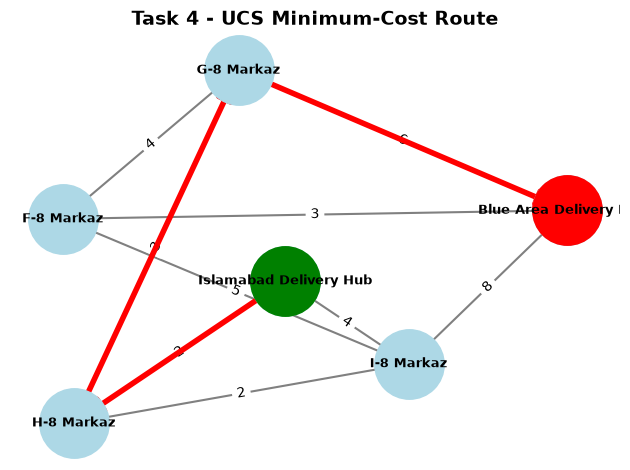

In [4]:
import heapq
import networkx as nx
import matplotlib.pyplot as plt

# TASK 4: UCS - DELIVERY ROUTE OPTIMIZATION
# Islamabad Delivery Hub -> Blue Area Delivery Point
# Different road segments have different costs

graph = {
    "Islamabad Delivery Hub": [
        ("I-8 Markaz", 4),
        ("H-8 Markaz", 2)
    ],
    "I-8 Markaz": [
        ("F-8 Markaz", 5),
        ("Blue Area Delivery Point", 8)
    ],
    "H-8 Markaz": [
        ("G-8 Markaz", 3),
        ("I-8 Markaz", 2)
    ],
    "G-8 Markaz": [
        ("F-8 Markaz", 4),
        ("Blue Area Delivery Point", 6)
    ],
    "F-8 Markaz": [
        ("Blue Area Delivery Point", 3)
    ],
    "Blue Area Delivery Point": []
}

def ucs(graph, start, goal):
    """
    Uniform Cost Search - expands node with lowest cumulative cost first.
    Returns: (traversal_order, solution_path, cost_dictionary)
    """
    # Priority Queue: stores (cumulative_cost, node)
    priority_queue = [(0, start)]
    
    # Best known cost to reach each node
    best_cost = {start: 0}
    
    # Parent dictionary for path reconstruction
    parent = {start: None}
    
    # Track traversal order
    traversal_order = []

    print(f"Initial PQ: {priority_queue}")
    print(f"Start: {start}, Goal: {goal}")
    print("-" * 50)

    step = 0
    while priority_queue:
        step += 1
        # Pop node with LOWEST cumulative cost
        current_cost, current = heapq.heappop(priority_queue)
        
        # Record traversal order
        traversal_order.append(current)
        
        # Goal test WHEN POPPED (guarantees optimal path)
        if current == goal:
            print(f"Step {step}: POP -> {current} (cost={current_cost})  *** GOAL FOUND ***")
            break
        
        # Skip if we already found a better path to this node
        if current in best_cost and current_cost > best_cost[current]:
            print(f"Step {step}: POP -> {current} (cost={current_cost}) SKIPPED (better path exists: {best_cost[current]})")
            continue
        
        print(f"Step {step}: POP -> {current} (cost={current_cost}) | EXPAND")
        
        # Expand neighbors
        for neighbor, edge_cost in graph[current]:
            new_cost = current_cost + edge_cost
            # Only add if this is the best known path to neighbor
            if neighbor not in best_cost or new_cost < best_cost[neighbor]:
                best_cost[neighbor] = new_cost
                parent[neighbor] = current
                heapq.heappush(priority_queue, (new_cost, neighbor))
                print(f"  Add {neighbor}: cost={new_cost} (via {current})")
        
        print(f"  PQ now: {priority_queue}")
        print()

    # Reconstruct Solution Path
    path = []
    node = goal
    if goal in parent:
        while node is not None:
            path.append(node)
            node = parent[node]
        path.reverse()
    else:
        path = []

    return traversal_order, path, best_cost


# Run UCS
start = "Islamabad Delivery Hub"
goal = "Blue Area Delivery Point"

order, path, costs = ucs(graph, start, goal)

# Display Results
print("=" * 60)
print(" RESULTS OF UCS SEARCH ")
print("=" * 60)
print(f"Start: {start}, Goal: {goal}")

print("\nTraversal / Expansion Order:")
for i, node in enumerate(order):
    print(f"  {i+1}. {node}")

print("\nSolution Path:")
print(" \u2192 ".join(path))

print(f"\nTotal Path Cost: {costs[goal]}")

# NetworkX Visualization
G = nx.DiGraph()

for node in graph:
    for neighbor, cost in graph[node]:
        G.add_edge(node, neighbor, weight=cost)

pos = nx.spring_layout(G, seed=42, k=2.5)

# Draw nodes
nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=2500)
nx.draw_networkx_nodes(G, pos, nodelist=[start], node_color='green', node_size=2500)
nx.draw_networkx_nodes(G, pos, nodelist=[goal], node_color='red', node_size=2500)

# Draw edges
nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=20, width=1.5)

# Labels
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold')

# Edge weight labels
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=10)

# Highlight solution path in RED
if len(path) > 1:
    path_edges = list(zip(path, path[1:]))
    nx.draw_networkx_edges(G, pos, edgelist=path_edges, edge_color='red', width=4, arrows=True, arrowsize=25)

plt.title("Task 4 - UCS Minimum-Cost Route", fontsize=14, fontweight='bold')
plt.axis("off")
plt.tight_layout()
plt.show()

## Task 5: Formal State-Space Modeling for Indoor Service Robot (Home Task)

## Task 6: Smart Building Navigation Agent (BFS vs DFS vs UCS Comparison)